In [1]:
from utils.snapwave_wrapper import compute_output_sites

# Preview the output-site points (isobaths from the topobathy + buoys from
# the JennBuoys GeoJSON) defined in NorthCarolina.json -> `output_sites`.
# No file is written here; the wrapper below drops `output_sites.{txt,csv}`
# into every case directory through `build_case`.
sites_df = compute_output_sites()
print("counts by source:", sites_df["source"].value_counts().to_dict())
sites_df.tail()

counts by source: {'isobath': 302, 'buoy': 35}


,lon,lat,source,source_id,source_label,depth,name
332,-76.66999,34.72000,buoy,buoy_8656483,levels,NaN,"Beaufort, Duke Marine Lab"
333,-77.78669,34.21329,buoy,buoy_8658163,levels,NaN,"Wrightsville Beach, Atlantic Ocean"
334,-78.91829,33.65499,buoy,buoy_8661070,levels,NaN,"Springmaid Pier, Atlantic Ocean"
335,-79.18669,33.35169,buoy,buoy_8662245,levels,NaN,"Oyster Landing, Crab Haul Creek"
336,-77.95330,34.22669,buoy,buoy_8658120,levels,NaN,"WILMINGTON, CAPE FEAR RIVER"


In [2]:
from utils.config import GOALS
from utils.simulations import generate_cases

cases_df = generate_cases(GOALS, num_samples_per_goal=5)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df

,goal,tp,wd,ds,zs
0,1,2.366899,97.523185,34.931395,-3.428109
1,1,8.526872,331.166322,37.716217,2.927121
2,1,13.461138,1.377956,11.969085,-0.053401
3,1,5.676751,299.421435,7.131886,1.465103
4,1,11.824683,120.155649,25.609594,-1.067239
...,...,...,...,...,...
65,14,2.366899,261.473649,34.931395,-3.428109
66,14,8.526872,132.589649,37.716217,2.927121
67,14,13.461138,163.405515,11.969085,-0.053401
68,14,5.676751,100.209864,7.131886,1.465103


<Axes: xlabel='tp', ylabel='wd'>

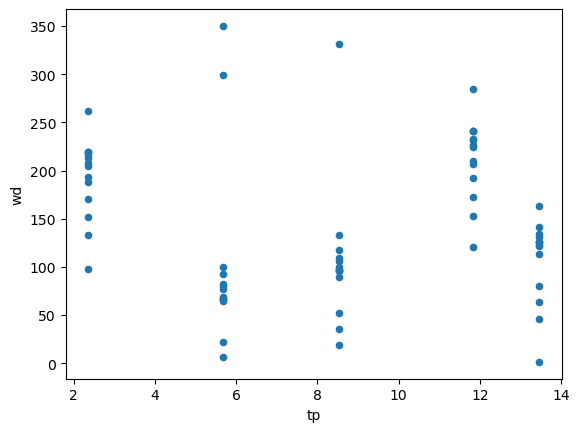

In [3]:
cases_df.plot.scatter(x="tp", y="wd")

In [4]:
from utils.snapwave_wrapper import NCSnapWaveMetaModelWrapper

# Same constructor signature as the bluemath_tk wrapper, plus auto-loading
# of the `output_sites` config: `build_case` will write
# `output_sites.{txt,csv}` into each case dir, and `postprocess_case` will
# relabel SnapWave stations as `10m_0`, `20m_65`, `buoy_41013`, ... using
# the per-case CSV.
snapwave_wrapper = NCSnapWaveMetaModelWrapper(
    templates_dir="templates-metamodel",
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={},
    output_dir="SnapWave_CASES_METAMODEL",
    aoi_file="inputs/AoI_Polygons/AoI_NorthCarolina.shp",
    goals_config=GOALS,
)
snapwave_wrapper

2026-06-16 13:33:05,579 - NCSnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-06-16 13:33:05,580 - NCSnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-06-16 13:33:05,580 - NCSnapWaveMetaModelWrapper - WARNING - Parameter wd is not in the default_parameters
2026-06-16 13:33:05,581 - NCSnapWaveMetaModelWrapper - WARNING - Parameter ds is not in the default_parameters
2026-06-16 13:33:05,581 - NCSnapWaveMetaModelWrapper - WARNING - Parameter zs is not in the default_parameters


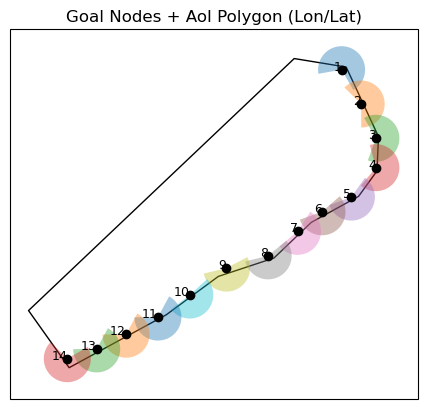

In [5]:
snapwave_wrapper.plot_configuration()

In [6]:
snapwave_wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [7]:
# snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [8]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    70
Name: count, dtype: int64

In [10]:
output = snapwave_wrapper.postprocess_cases()
output

<xarray.Dataset> Size: 582kB
Dimensions:         (case_num: 70, stations: 337)
Coordinates:
  * case_num        (case_num) int64 560B 0 1 2 3 4 5 6 ... 63 64 65 66 67 68 69
    goal            (case_num) int64 560B 1 1 1 1 1 2 2 ... 13 13 14 14 14 14 14
    station_name    (stations) object 3kB '10m_0' '10m_1' ... 'buoy_8658120'
    station_x       (stations) float32 1kB -76.23 -76.19 ... -79.19 -77.95
    station_y       (stations) float32 1kB 37.0 36.99 36.98 ... 33.35 34.23
    point_zb        (stations) float32 1kB nan nan nan nan ... nan nan nan nan
    station_source  (stations) object 3kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    station_label   (stations) object 3kB '10m' '10m' ... 'levels' 'levels'
    station_depth   (stations) float64 3kB -10.0 -10.0 -10.0 ... nan nan nan
Dimensions without coordinates: stations
Data variables:
    point_zs        (case_num, stations) float32 94kB 0.0 0.0 ... 0.0 0.05089
    point_hm0       (case_num, stations) float32 94kB 0.0 0.0 ... 0.0 0.000707
    point_tp        (case_num, stations) float32 94kB 0.0 0.0 0.0 ... 0.0 11.82
    point_wavdir    (case_num, stations) float32 94kB 270.0 270.0 ... 280.0
    point_dw        (case_num, stations) float32 94kB 0.0 0.0 0.0 ... 0.0 0.0
    point_df        (case_num, stations) float32 94kB 0.0 0.0 ... 0.0 4.748e-11
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output